In [1]:
import os
import numpy as np
import xarray as xr
import zipfile
from pathlib import Path
import pandas as pd
import sys 
sys.path.append("../")
import matplotlib.pyplot as plt
from cartopy import crs as ccrs
import cartopy.feature as feature
from matplotlib.colors import TwoSlopeNorm
import glob
import cmocean as cm
import matplotlib.dates as mdates
import gsw


In [2]:
path = "Z:\MD252_WHIRLS\DAILY_adt_sst_toeddies_data"
file = "2026-06-29_L4_SST_grib.zip"

zip_path = os.path.join(path, file)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    print("\n".join(zip_ref.namelist()))

<>:1: SyntaxWarning: invalid escape sequence '\M'
<>:1: SyntaxWarning: invalid escape sequence '\M'
/var/folders/08/g_gjz7kj0db8g7wf0vbs2mjw0000gn/T/ipykernel_6274/3162399333.py:1: SyntaxWarning: invalid escape sequence '\M'
  path = "Z:\MD252_WHIRLS\DAILY_adt_sst_toeddies_data"
/var/folders/08/g_gjz7kj0db8g7wf0vbs2mjw0000gn/T/ipykernel_6274/3162399333.py:1: SyntaxWarning: invalid escape sequence '\M'
  path = "Z:\MD252_WHIRLS\DAILY_adt_sst_toeddies_data"


FileNotFoundError: [Errno 2] No such file or directory: 'Z:\\MD252_WHIRLS\\DAILY_adt_sst_toeddies_data/2026-06-29_L4_SST_grib.zip'

In [3]:
extract_dir = Path("../temp_nc")

with zipfile.ZipFile(zip_path) as z:
    z.extractall(extract_dir)

datasets = []
for nc in extract_dir.rglob("*.nc"):
    datasets.append(xr.open_dataset(nc))

In [4]:
datasets[3]

<xarray.Dataset>
Dimensions:    (time: 1799)
Coordinates:
    longitude  (time) float64 ...
    latitude   (time) float64 ...
  * time       (time) datetime64[ns] 2026-06-28T00:01:42.568374016 ... 2026-0...
Data variables:
    mdt        (time) float64 ...
Attributes: (12/23)
    institution:                       CLS, CNES
    doi:                               https://doi.org/10.48670/moi-00147
    time_coverage_start:               2026-06-28T00:01:42.568374Z
    time_coverage_end:                 2026-06-28T09:53:10.644055Z
    last_date_observation:             2026-06-28T09:53:10.644055Z
    geospatial_lat_min:                -44.49534
    ...                                ...
    product_id:                        SEALEVEL_GLO_PHY_L3_NRT_008_044
    dataset_id:                        cmems_obs-sl_glo_phy-ssh_nrt_j3g-l3-du...
    Conventions:                       CF-1.9 ACDD-1.3
    title:                             Subset of dataset cmems_obs-sl_glo_phy...
    contact:                           servicedesk.cmems@mercator-ocean.eu
    history:                           2026-06-29T12:30:12.543386: Subset fro...

In [10]:
print(os.getcwd())

c:\Users\Paul\OneDrive\Bureau\WHIRLS


In [14]:
path = Path(
    r"Z:\MD252_WHIRLS\MVP_Data_processed\transect 1\MVP__profile_000.csv"
)

df = pd.read_csv(path)

In [15]:
df

,PRES (dbar),TEMP (°C),SAL (psu),COND (mS/cm),OXY (µmol/L),TIME,FLUO (ug/L),TURB (NTU),PH,NO3 (µmol/L),LAT (°N),LON (°E)
0,4.068467,17.520624,35.423818,45.909679,236.581243,2026-06-29 10:04:31.263426,0.73800,0.23079,6.321877,1.395422,-34.500207,17.835046
1,3.899130,17.518644,35.423818,45.908283,236.416818,2026-06-29 10:04:32.187148,0.73800,0.22600,6.321867,1.435815,-34.500207,17.835046
2,3.472800,17.517860,35.423818,45.907756,236.593684,2026-06-29 10:04:32.440219,0.72956,0.22600,6.321873,1.367786,-34.500207,17.835046
3,3.716320,17.517906,35.423818,45.907745,236.596492,2026-06-29 10:04:32.508226,0.72600,0.22600,6.321873,1.534080,-34.500207,17.835046
4,4.307417,17.517904,35.423905,45.908600,236.512719,2026-06-29 10:04:33.896208,0.72600,0.22800,6.321869,1.569674,-34.500207,17.835046
...,...,...,...,...,...,...,...,...,...,...,...,...
1656,401.742000,6.494390,34.476542,34.527812,210.552601,2026-06-29 10:07:00.541089,0.62400,0.21600,6.022861,24.931075,-34.500207,17.835046
1657,401.956500,6.493372,34.476537,34.526523,210.574889,2026-06-29 10:07:00.641099,0.62400,0.21600,6.022845,24.995554,-34.500207,17.835046
1658,402.137000,6.492911,34.476535,34.525797,210.583937,2026-06-29 10:07:00.716107,0.62400,0.21600,6.022840,25.049813,-34.500207,17.835046
1659,402.393000,6.492691,34.476532,34.525149,210.594227,2026-06-29 10:07:00.816118,0.62400,0.21600,6.022833,25.049813,-34.500207,17.835046


# Map ADT

In [26]:
ds = xr.open_dataset('20260701_Copernicus_PHY.nc')
lon_min = -5
lon_max = 25
lat_min = -45
lat_max = -30
ds = ds.where((ds.latitude >= lat_min) & (ds.latitude <= lat_max) & 
                       (ds.longitude >= lon_min) & (ds.longitude <= lon_max),
                       drop=True)

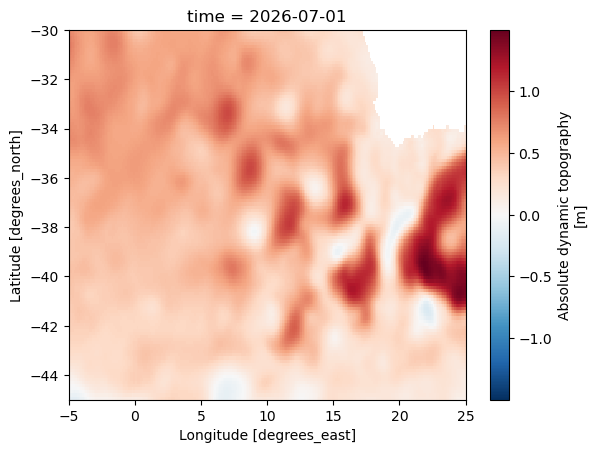

In [27]:
ds.adt[0,:,:].plot()

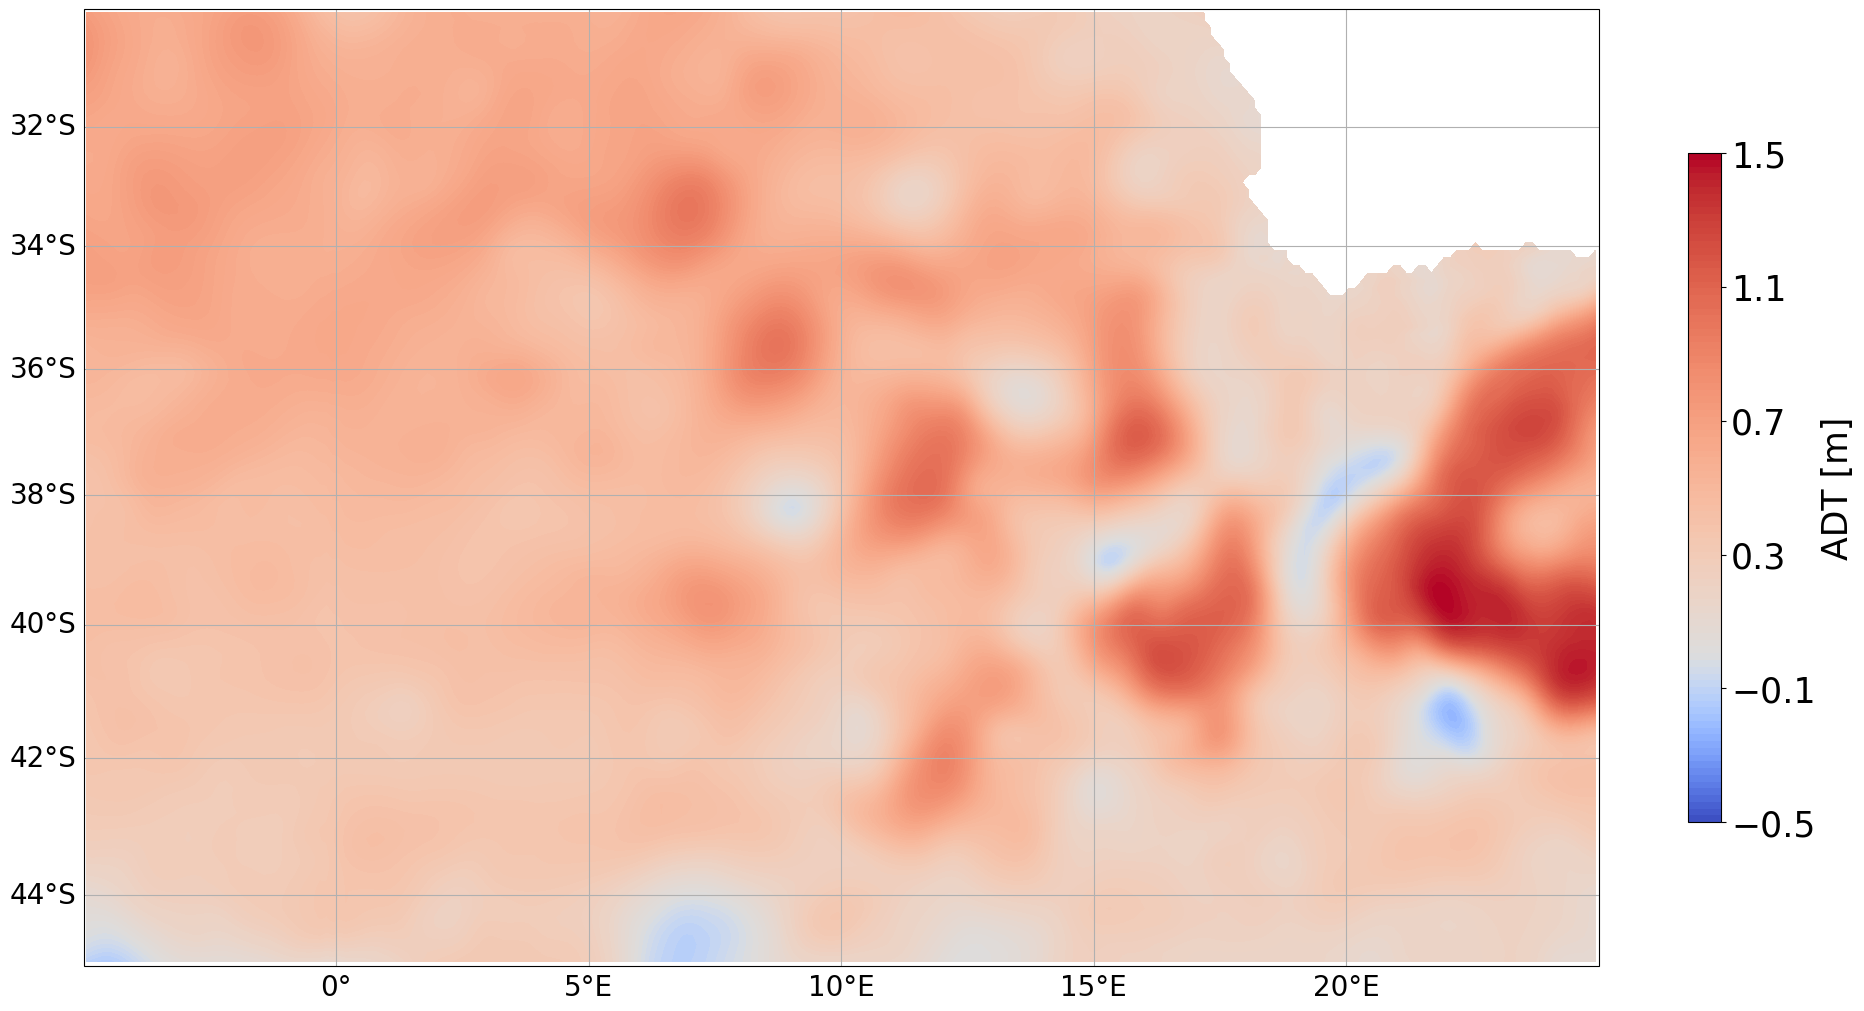

In [31]:
var_to_plot = 'ADT'
label = '[m]'
ccrs_land = feature.NaturalEarthFeature('physical', 'land', '110m',
                                        edgecolor='black',
                                        facecolor='grey',
                                        linewidth=0.5)


levels = 100
vmin = -0.5
vmax = 1.5
level_boundaries = np.linspace(vmin, vmax, levels)
norm = TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)

fig, axs = plt.subplots(
    nrows=1, ncols=1, figsize=(25, 10),
    subplot_kw={'projection': ccrs.Mercator()}, constrained_layout=True
)

axs.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
gl = axs.gridlines(draw_labels=True, dms=False, x_inline=False, y_inline=False)
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 20, 'color': 'black'}
gl.ylabel_style = {'size': 20, 'color': 'black'}
contour = axs.contourf(
        ds.longitude.values, ds.latitude.values, ds.adt[0,:,:], levels=level_boundaries,
        norm=norm, cmap='coolwarm', transform=ccrs.PlateCarree())


# axs.add_feature(ccrs_land)

ticks = np.linspace(vmin, vmax, 6)
cbar = fig.colorbar(contour, ax=axs, orientation='vertical', fraction=0.015, pad=0.04)
cbar.set_label(f'{var_to_plot} ' + label, fontsize=25)
cbar.set_ticks(ticks)
cbar.ax.tick_params(labelsize=25)
# plt.savefig(f'../../paper/fig01.pdf', dpi=900, bbox_inches='tight')
plt.show()

# SWOT

In [2]:
swot_52_320 = xr.open_dataset('data/SWOT/SWOT_L3_LR_SSH_Expert_052_320_20260630T172426_20260630T181553_v3.0.nc')
swot_52_333 = xr.open_dataset('data/SWOT/SWOT_L3_LR_SSH_Expert_052_333_20260701T043315_20260701T052442_v3.0.nc')
swot_52_348 = xr.open_dataset('data/SWOT/SWOT_L3_LR_SSH_Expert_052_348_20260701T172458_20260701T181624_v3.0.nc')
swot_52_361 = xr.open_dataset('data/SWOT/SWOT_L3_LR_SSH_Expert_052_361_20260702T043346_20260702T052513_v3.0.nc')
swot_52_376 = xr.open_dataset('data/SWOT/SWOT_L3_LR_SSH_Expert_052_376_20260702T172529_20260702T181655_v3.0.nc')
swot_52_389 = xr.open_dataset('data/SWOT/SWOT_L3_LR_SSH_Expert_052_389_20260703T043417_20260703T052544_v3.0.nc')
swot_52_404 = xr.open_dataset('data/SWOT/SWOT_L3_LR_SSH_Expert_052_404_20260703T172559_20260703T181726_v3.0.nc')

In [3]:
tracks = [
    swot_52_320,
    swot_52_333,
    swot_52_348,
    swot_52_361,
    swot_52_376,
    swot_52_389,
    swot_52_404
]

NameError: name 'swot_52_320' is not defined

In [4]:
for ds in tracks:
    ds['longitude'] = ((ds.longitude + 180) % 360) - 180

In [5]:
def dmm_to_dd(degrees, minutes, hemisphere=None):
    dd = degrees + minutes / 60
    return dd

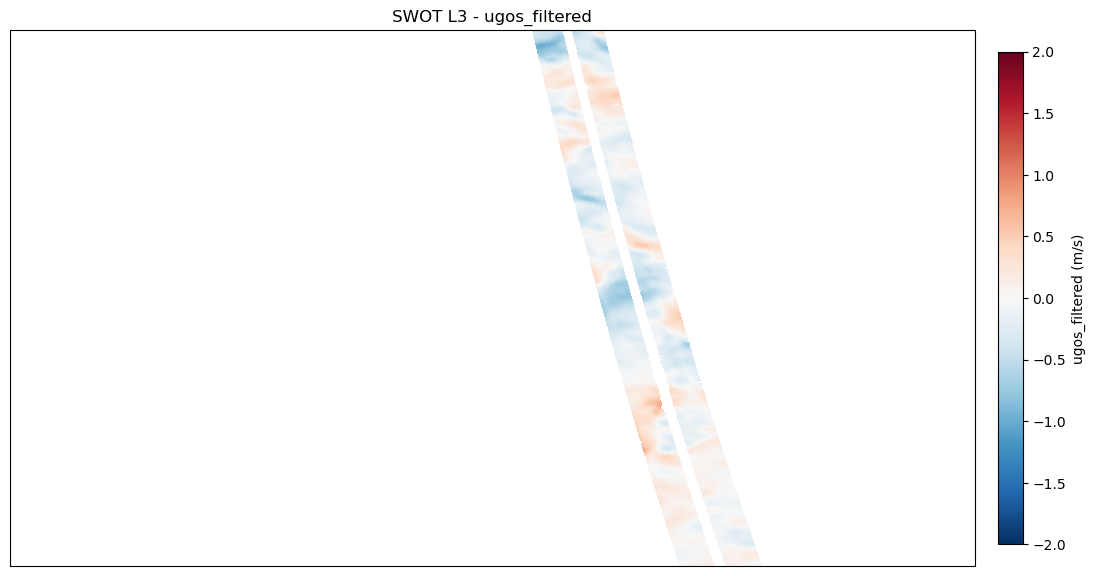

In [ ]:
fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
pcm = ax.pcolormesh(
    swot_52_320.longitude,
    swot_52_320.latitude,
    swot_52_320.ugos_filtered,
    transform=ccrs.PlateCarree(),
    shading="auto",
    cmap="RdBu_r",
    vmin=-2, vmax=2
)
ax.set_extent([6, 24, -43, -33], crs=ccrs.PlateCarree())
cbar = plt.colorbar(
    pcm,
    ax=ax,
    orientation="vertical",
    pad=0.02,
    shrink=0.8
)
cbar.set_label("ugos_filtered (m/s)")
ax.set_title("SWOT L3 - ugos_filtered")
plt.show()

In [6]:
ship_lat_st_22 = dmm_to_dd(-39, 13.517)
ship_lon_st_22 = dmm_to_dd(11, 38.780)

In [7]:
lon_min, lon_max = 6, 24
lat_min, lat_max = -43, -33

In [8]:
def subset_track(ds, lon_min, lon_max, lat_min, lat_max):

    lon = ds.longitude
    lat = ds.latitude

    mask = (
        (lon >= lon_min) &
        (lon <= lon_max) &
        (lat >= lat_min) &
        (lat <= lat_max)
    )

    return ds.where(mask, drop=True)

In [9]:
# ATTENTION CELA CHANGE LES DIM DES VARIABLES 1D
tracks_cut = [
    subset_track(ds, lon_min, lon_max, lat_min, lat_max)
    for ds in tracks
]

In [10]:
def get_track_start(ds, lon_min=lon_min, lon_max=lon_max, lat_min=lat_min, lat_max=lat_max):

    lon = ds.longitude.values
    lat = ds.latitude.values

    mask = (
        (lon >= lon_min) &
        (lon <= lon_max) &
        (lat >= lat_min) &
        (lat <= lat_max)
    )

    # premier point valide dans la zone
    idx = np.where(mask.flatten())[0]

    if len(idx) == 0:
        return None, None

    i0 = idx[0]

    return lon.flatten()[i0], lat.flatten()[i0]

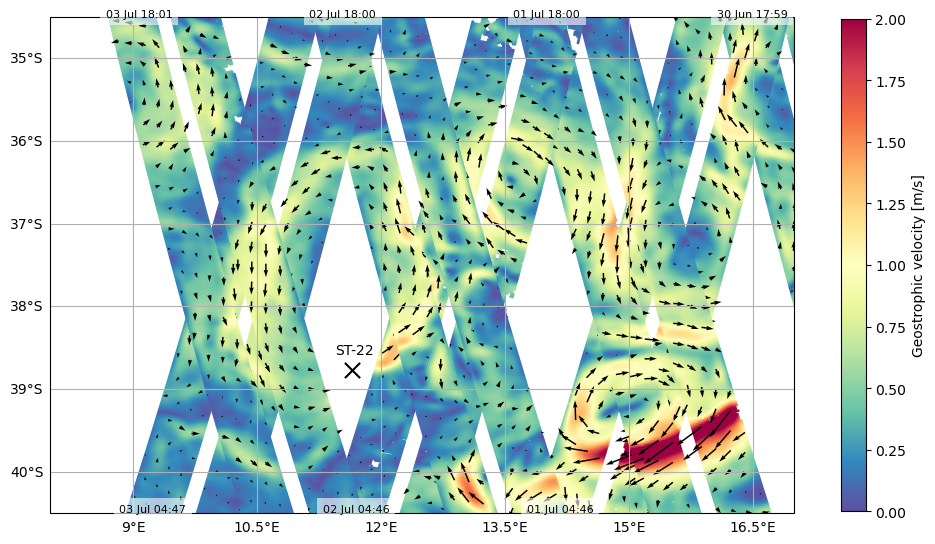

In [ ]:
# -----------------------------
# PARAMÈTRES ZONE
# -----------------------------
# lon_min, lon_max = 6, 24
# lat_min, lat_max = -43, -33

lon_min, lon_max = 8, 17
lat_min, lat_max = -40.5, -34.5

# -----------------------------
# FIGURE
# -----------------------------
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

# -----------------------------
# ZOOM
# -----------------------------
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

# -----------------------------
# LOOP TRACKS
# -----------------------------
for ds_cut, ds_full in zip(tracks_cut, tracks):

    # ---- coordonnées
    lon = ds_cut.longitude.values
    lat = ds_cut.latitude.values

    # ---- vitesse
    ugos = ds_cut.ugos_filtered.values.flatten()
    vgos = ds_cut.vgos_filtered.values.flatten()
    vel = np.sqrt(ugos**2 + vgos**2)

    # calc the strain etc

    sc = ax.scatter(
        lon.flatten(),
        lat.flatten(),
        c=vel,
        s=1,
        cmap="Spectral_r",
        vmin=0,
        vmax=2,
        transform=ccrs.PlateCarree()
    )

    step = 100
    vecteurs = ax.quiver(
        lon.flatten()[::step],
        lat.flatten()[::step],
        ugos[::step],
        vgos[::step],
        color="black",
        scale=5.e1,
        width=0.002,
        transform=ccrs.PlateCarree()
    )

    # -----------------------------
    # DATE (PROPRE, SANS IDX)
    # -----------------------------
    t = pd.to_datetime(ds_cut.time.values)
    t_valid = t[~pd.isna(t)]
    first_time = t_valid[0]
    first_time = first_time.strftime("%d %b %H:%M")

    # t = pd.to_datetime(ds_full.time.values)
    # t = t[~pd.isna(t)]

    # date_str = t[0].strftime("%d %b")
    # start_time = t[0].strftime("%H:%M")

    # -----------------------------
    # POSITION DEBUT TRACK (ZONE)
    # -----------------------------
    mask = (
        (ds_full.longitude.values >= lon_min) &
        (ds_full.longitude.values <= lon_max) &
        (ds_full.latitude.values >= lat_min) &
        (ds_full.latitude.values <= lat_max)
    )

    idx = np.where(mask.flatten())[0]

    if len(idx) > 0:
        i0 = idx[0]

        x0 = ds_full.longitude.values.flatten()[i0]
        y0 = ds_full.latitude.values.flatten()[i0]

        ax.text(
            x0, y0,
            f"{first_time}",
            fontsize=8,
            color="black",
            transform=ccrs.PlateCarree(),
            bbox=dict(facecolor="white", alpha=0.6, edgecolor="none")
        )

# -----------------------------
# SHIP
# -----------------------------
ax.scatter(
    ship_lon_st_22,
    ship_lat_st_22,
    color="black",
    s=120,
    marker="x",
    transform=ccrs.PlateCarree()
)

ax.text(
    ship_lon_st_22 - 0.2,
    ship_lat_st_22 + 0.2,
    "ST-22",
    fontsize=10,
    color="black",
    transform=ccrs.PlateCarree()
)

# -----------------------------
# GRID
# -----------------------------
gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

# -----------------------------
# COLORBAR (COMMUNE)
# -----------------------------
cbar = plt.colorbar(sc, ax=ax, shrink=0.8)
cbar.set_label("Geostrophic velocity [m/s]")

# -----------------------------
# TITLE
# -----------------------------
# ax.set_title("SWOT L3 (subset + correct time labels)")

plt.show()

# MVP

In [2]:
mvp_ox = xr.open_dataset('data/MVP/section_2_3_OX.nc')
mvp_sal = xr.open_dataset('data/MVP/section_2_3_SAL.nc')
mvp_suna = xr.open_dataset('data/MVP/section_2_3_SUNA.nc')
mvp_temp = xr.open_dataset('data/MVP/section_2_3_TEMP.nc')

In [3]:
dates = mdates.num2date(mvp_ox.date)

In [4]:
def add_time_axis(ax, ds):
    ax_time = ax.twiny()

    # déplacer l’axe en bas
    ax_time.xaxis.set_label_position('bottom')
    ax_time.xaxis.tick_bottom()
    ax_time.spines['bottom'].set_position(('outward', 40))

    # conversion dates matplotlib → datetime
    time = mdates.num2date(ds.date.values)

    ax_time.set_xlim(time[0], time[-1])
    ax_time.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d-%H'))

    ax_time.set_xlabel("Time")
    ax_time.tick_params(axis='x', rotation=45)

    return ax_time

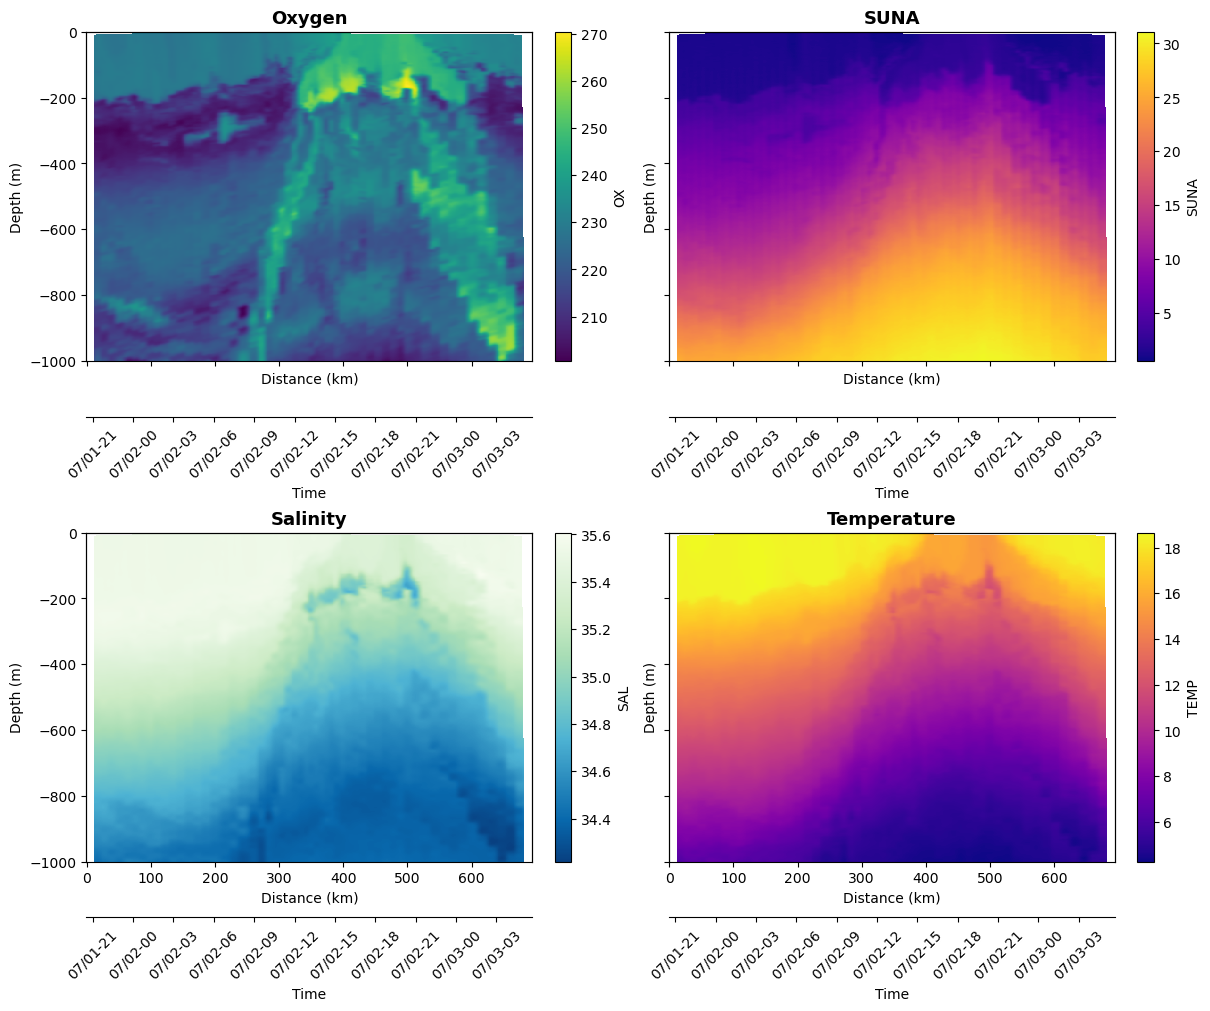

In [5]:
fig, ax = plt.subplots(
    2, 2,
    figsize=(12, 10),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

plots = [
    (mvp_ox,   "OX",   "Oxygen",      "viridis"),
    (mvp_suna, "SUNA", "SUNA",        "plasma"),
    (mvp_sal,  "SAL",  "Salinity",    "GnBu_r"),   # si cmocean est installé
    (mvp_temp, "TEMP", "Temperature", "plasma")   # si cmocean est installé
]

for axi, (ds, var, title, cmap) in zip(ax.flat, plots):

    pcm = axi.pcolormesh(
        ds.distance,
        -ds.depth,
        ds[var],
        shading="auto",
        cmap=cmap
    )

    # axi.invert_yaxis()

    axi.set_title(title, fontsize=13, fontweight="bold")
    axi.set_xlabel("Distance (km)")
    axi.set_ylabel("Depth (m)")

    cbar = fig.colorbar(pcm, ax=axi)
    cbar.set_label(var)

    add_time_axis(axi, ds)
    

plt.show()

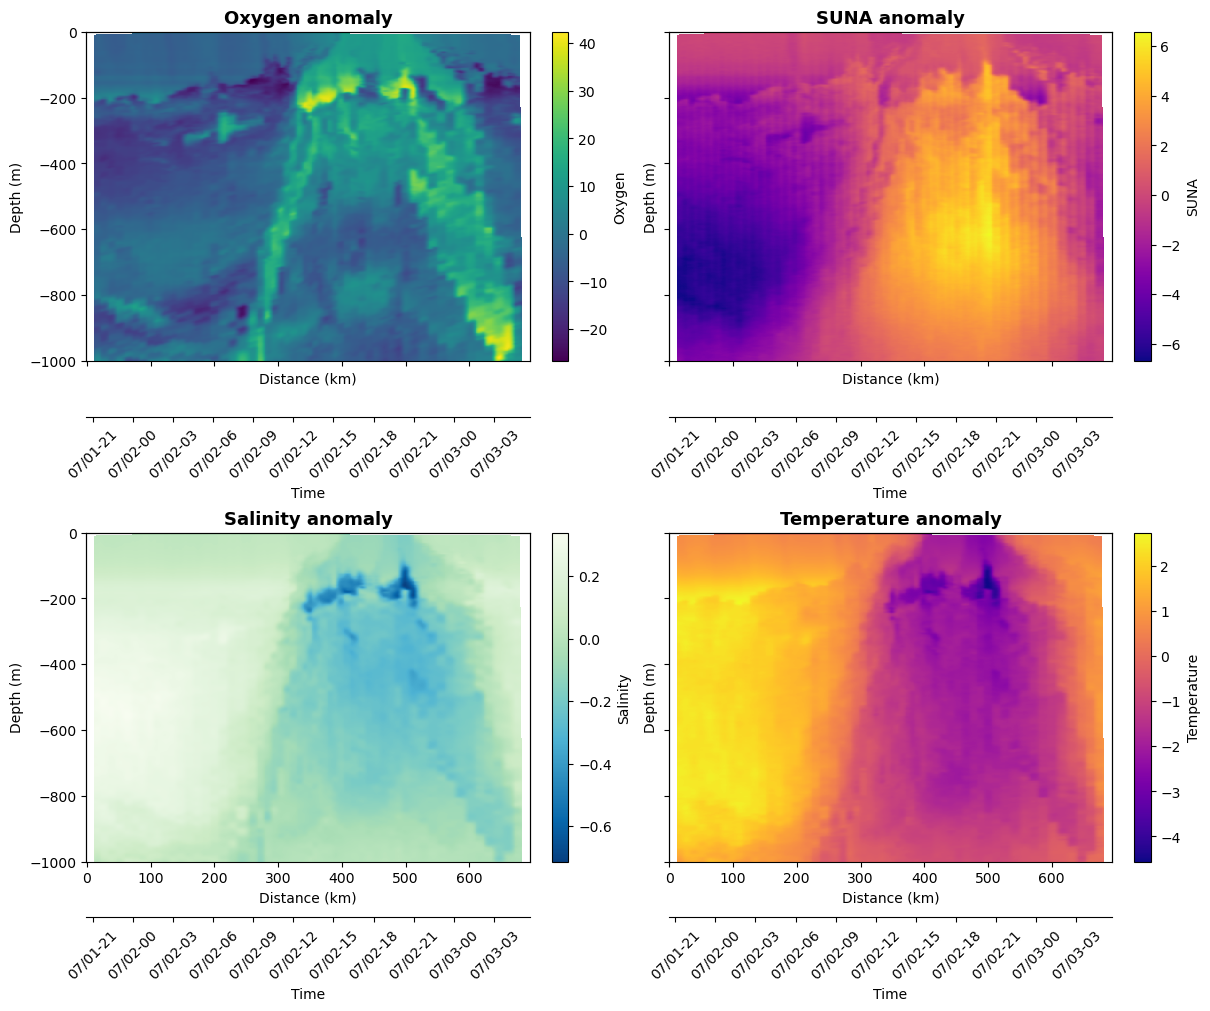

In [6]:
fig, ax = plt.subplots(
    2, 2,
    figsize=(12, 10),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

plots = [
    (mvp_ox, mvp_ox.OX - mvp_ox.OX.mean(dim="distance", skipna=True),   "Oxygen",      "viridis"),
    (mvp_suna, mvp_suna.SUNA - mvp_suna.SUNA.mean(dim="distance", skipna=True), "SUNA",        "plasma"),
    (mvp_sal, mvp_sal.SAL - mvp_sal.SAL.mean(dim="distance", skipna=True),  "Salinity",    "GnBu_r"),   # si cmocean est installé
    (mvp_temp, mvp_temp.TEMP - mvp_temp.TEMP.mean(dim="distance", skipna=True), "Temperature", "plasma")   # si cmocean est installé
]

for axi, (ds, var, title, cmap) in zip(ax.flat, plots):

    pcm = axi.pcolormesh(
        ds.distance,
        -ds.depth,
        var,
        shading="auto",
        cmap=cmap
    )

    # axi.invert_yaxis()

    axi.set_title(title + ' anomaly', fontsize=13, fontweight="bold")
    axi.set_xlabel("Distance (km)")
    axi.set_ylabel("Depth (m)")

    cbar = fig.colorbar(pcm, ax=axi)
    cbar.set_label(title)

    add_time_axis(axi, ds)
    

plt.show()

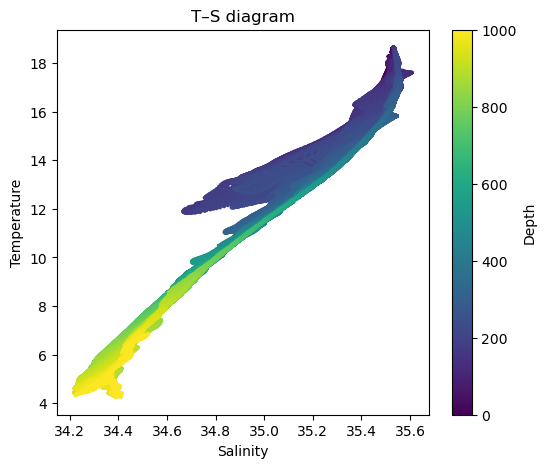

In [7]:
T = mvp_temp.TEMP.values
S = mvp_sal.SAL.values
Z = mvp_temp.depth.values[:, None]  # broadcast 2D

plt.figure(figsize=(6,5))

sc = plt.scatter(
    S.ravel(),
    T.ravel(),
    c=np.repeat(mvp_temp.depth.values, mvp_temp.distance.size),
    cmap="viridis",
    s=2
)

# plt.gca().invert_yaxis()
plt.colorbar(label="Depth")
plt.xlabel("Salinity")
plt.ylabel("Temperature")
plt.title("T–S diagram")
plt.show()

In [8]:
z = mvp_temp.depth.values

dT_dz = np.gradient(mvp_temp.TEMP.values, z, axis=0)
dS_dz = np.gradient(mvp_sal.SAL.values, z, axis=0)
dO2_dz = np.gradient(mvp_ox.OX.values, z, axis=0)
dNO3_dz = np.gradient(mvp_suna.SUNA.values, z, axis=0)

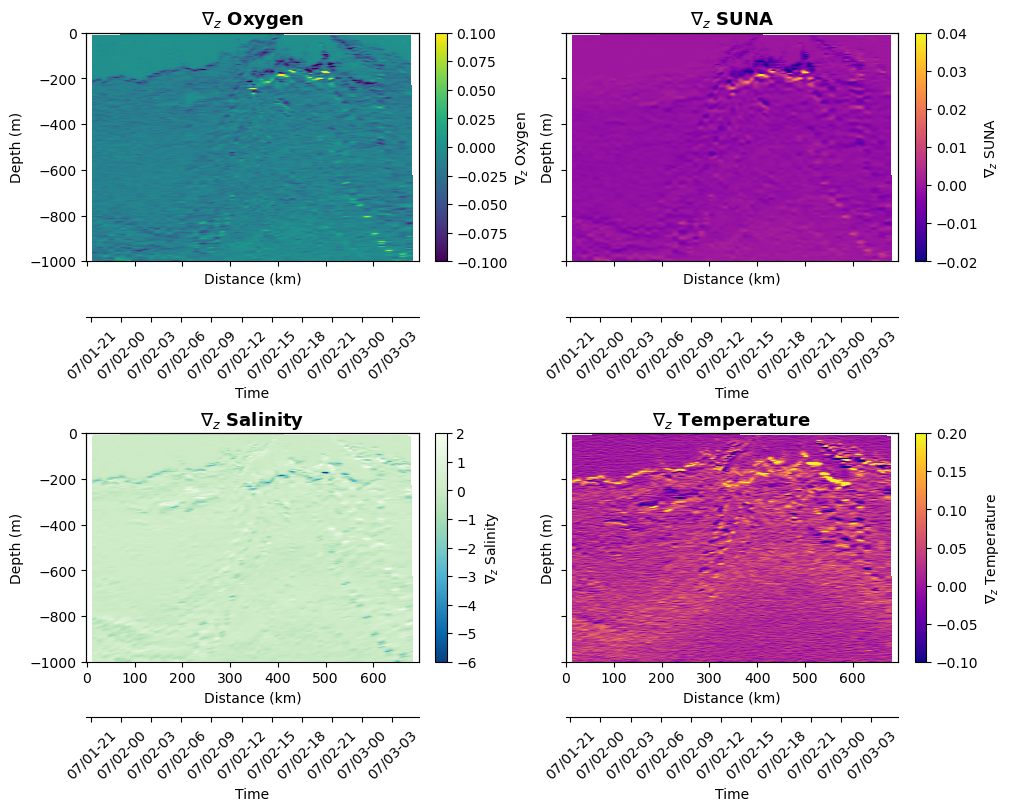

In [20]:
fig, ax = plt.subplots(
    2, 2,
    figsize=(10, 8),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

plots = [
    (mvp_ox, dT_dz,   r"$\nabla_z$ Oxygen",      "viridis", -0.1, 0.1),
    (mvp_suna, dS_dz, r"$\nabla_z$ SUNA",        "plasma", -0.02, 0.04),
    (mvp_sal, dO2_dz,  r"$\nabla_z$ Salinity",    "GnBu_r", -6, 2),   # si cmocean est installé
    (mvp_temp, dNO3_dz, r"$\nabla_z$ Temperature", "plasma", -0.1, 0.2)   # si cmocean est installé
]

for axi, (ds, var, title, cmap, vmin, vmax) in zip(ax.flat, plots):

    pcm = axi.pcolormesh(
        ds.distance,
        -ds.depth,
        var,
        shading="auto",
        cmap=cmap,
        vmin=vmin, vmax=vmax,
    )

    # axi.invert_yaxis()

    axi.set_title(title, fontsize=13, fontweight="bold")
    axi.set_xlabel("Distance (km)")
    axi.set_ylabel("Depth (m)")

    cbar = fig.colorbar(pcm, ax=axi)
    cbar.set_label(title)

    add_time_axis(axi, ds)

plt.show()

In [21]:
x = mvp_temp.distance.values

dT_dx = np.gradient(mvp_temp.TEMP.values, x, axis=1)
dS_dx = np.gradient(mvp_sal.SAL.values, x, axis=1)
dO2_dx = np.gradient(mvp_ox.OX.values, x, axis=1)
dNO3_dx = np.gradient(mvp_suna.SUNA.values, x, axis=1)

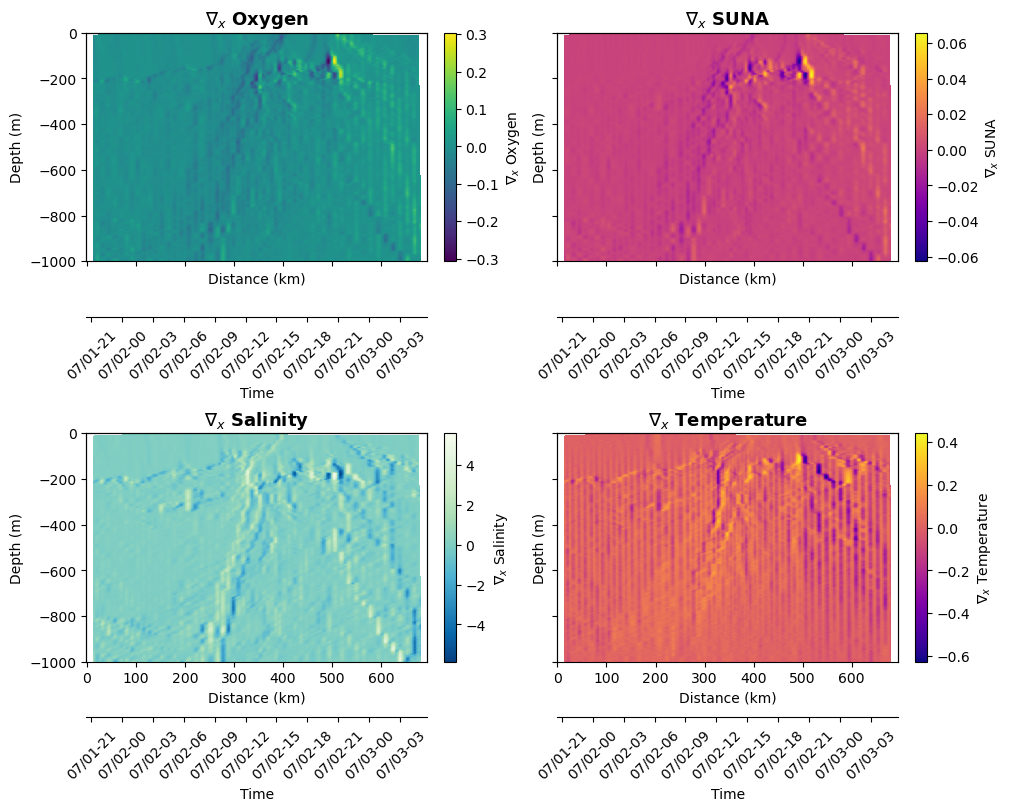

In [22]:
fig, ax = plt.subplots(
    2, 2,
    figsize=(10, 8),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

plots = [
    (mvp_ox, dT_dx,   r"$\nabla_x$ Oxygen",      "viridis"),
    (mvp_suna, dS_dx, r"$\nabla_x$ SUNA",        "plasma"),
    (mvp_sal, dO2_dx,  r"$\nabla_x$ Salinity",    "GnBu_r"),   # si cmocean est installé
    (mvp_temp, dNO3_dx, r"$\nabla_x$ Temperature", "plasma")   # si cmocean est installé
]

for axi, (ds, var, title, cmap) in zip(ax.flat, plots):

    pcm = axi.pcolormesh(
        ds.distance,
        -ds.depth,
        var,
        shading="auto",
        cmap=cmap,
    )

    # axi.invert_yaxis()

    axi.set_title(title, fontsize=13, fontweight="bold")
    axi.set_xlabel("Distance (km)")
    axi.set_ylabel("Depth (m)")

    cbar = fig.colorbar(pcm, ax=axi)
    cbar.set_label(title)

    add_time_axis(axi, ds)

plt.show()

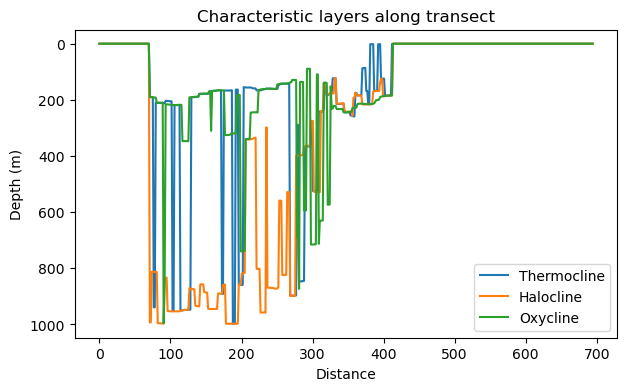

In [10]:
thermocline = np.argmax(np.abs(dT_dz), axis=0)
halocline = np.argmax(np.abs(dS_dz), axis=0)
oxycline = np.argmax(np.abs(dO2_dz), axis=0)

plt.figure(figsize=(7,4))

plt.plot(mvp_temp.distance, z[thermocline], label="Thermocline")
plt.plot(mvp_temp.distance, z[halocline], label="Halocline")
plt.plot(mvp_temp.distance, z[oxycline], label="Oxycline")

plt.gca().invert_yaxis()
plt.xlabel("Distance")
plt.ylabel("Depth (m)")
plt.legend()
plt.title("Characteristic layers along transect")
plt.show()

In [ ]:
lat = mvp_ox.lat

# -----------------------------
# 1. DEPTH -> PRESSURE
# -----------------------------
p = gsw.p_from_z(-mvp_ox.depth, lat)  # (depth,)

# -----------------------------
# 2. TEOS-10 DENSITY
# -----------------------------
lon = mvp_ox.lon
# p_2D = xr.DataArray(
#     p,
#     dims=mvp_temp.TEMP.dims,
#     coords=mvp_temp.TEMP.coords
# )

SA = gsw.SA_from_SP(mvp_sal.SAL, p, mvp_sal.lon, mvp_sal.lat)
CT = gsw.CT_from_t(SA, mvp_temp.TEMP.values, p)
rho = gsw.rho(SA, CT, p)  # (time, depth, lon)


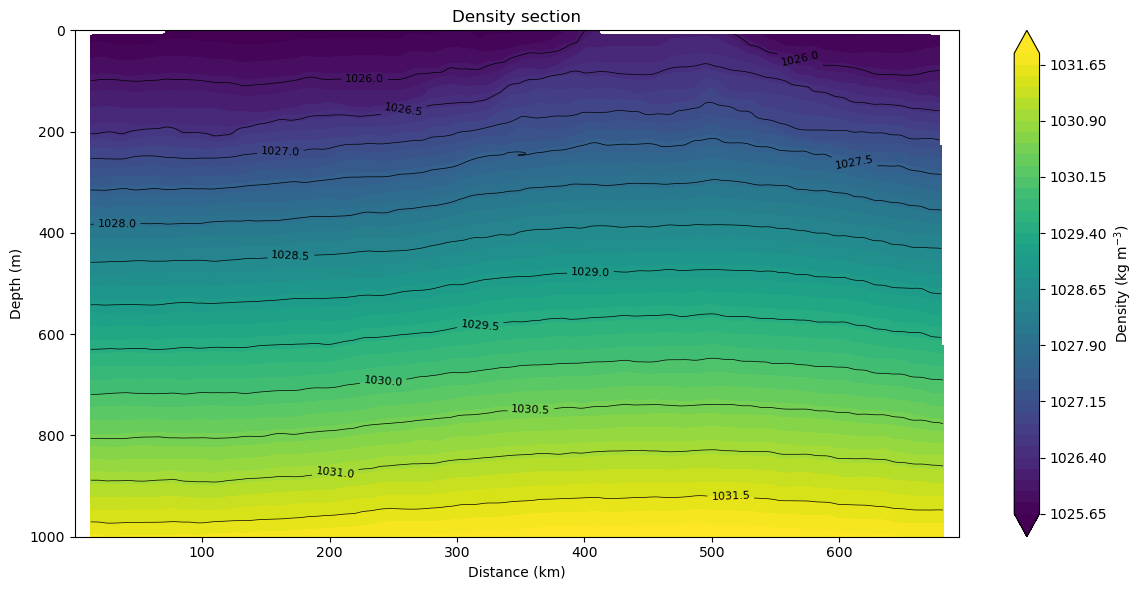

In [55]:
fig, ax = plt.subplots(figsize=(12,6))

# Champ de densité
cf = ax.contourf(
    rho.distance,
    rho.depth,
    rho,
    levels=50,
    cmap="viridis",
    extend="both"
)

# Isopycnes
cs = ax.contour(
    rho.distance,
    rho.depth,
    rho,
    levels=np.arange(np.floor(rho.min()), np.ceil(rho.max()), 0.5),
    colors="k",
    linewidths=0.5
)

ax.clabel(cs, fmt="%.1f", fontsize=8)

cb = plt.colorbar(cf, ax=ax)
cb.set_label(r"Density (kg m$^{-3}$)")

ax.invert_yaxis()
ax.set_xlabel("Distance (km)")
ax.set_ylabel("Depth (m)")
ax.set_title("Density section")

plt.tight_layout()
plt.show()

In [ ]:
SA = gsw.SA_from_SP(mvp_sal.SAL, p, mvp_sal.lon, mvp_sal.lat)
CT = gsw.CT_from_t(SA, mvp_temp.TEMP.values, p)
sigma0 = gsw.sigma0(SA, CT)

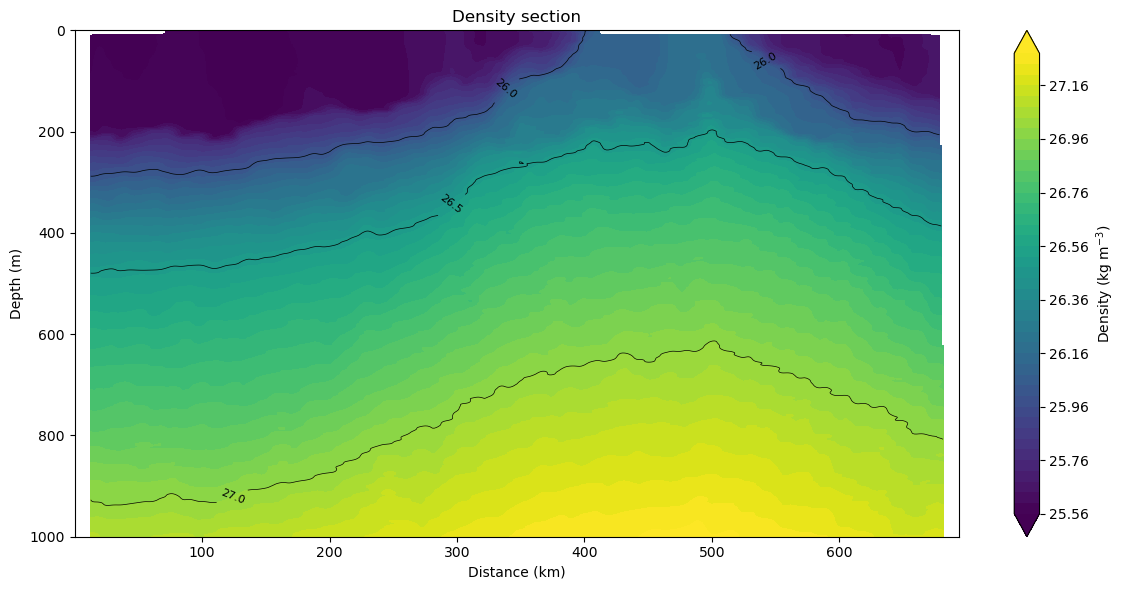

In [52]:
fig, ax = plt.subplots(figsize=(12,6))

# Champ de densité
cf = ax.contourf(
    sigma0.distance,
    sigma0.depth,
    sigma0,
    levels=50,
    cmap="viridis",
    extend="both"
)

# Isopycnes
cs = ax.contour(
    sigma0.distance,
    sigma0.depth,
    sigma0,
    levels=np.arange(np.floor(sigma0.min()), np.ceil(sigma0.max()), 0.5),
    colors="k",
    linewidths=0.5
)

ax.clabel(cs, fmt="%.1f", fontsize=8)

cb = plt.colorbar(cf, ax=ax)
cb.set_label(r"Density (kg m$^{-3}$)")

ax.invert_yaxis()
ax.set_xlabel("Distance (km)")
ax.set_ylabel("Depth (m)")
ax.set_title("Density section")

plt.tight_layout()
plt.show()

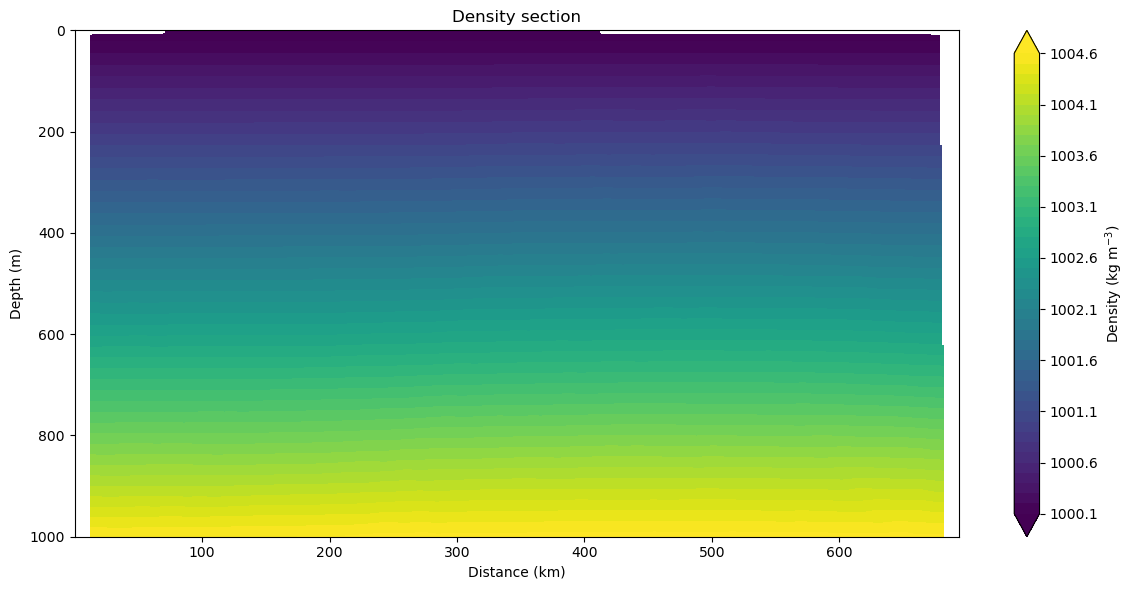

In [53]:
fig, ax = plt.subplots(figsize=(12,6))

# Champ de densité
cf = ax.contourf(
    sigma0.distance,
    sigma0.depth,
    rho - sigma0,
    levels=50,
    cmap="viridis",
    extend="both"
)


cb = plt.colorbar(cf, ax=ax)
cb.set_label(r"Density (kg m$^{-3}$)")

ax.invert_yaxis()
ax.set_xlabel("Distance (km)")
ax.set_ylabel("Depth (m)")
ax.set_title("Density section")

plt.tight_layout()
plt.show()